# TP 2 : Simulation Multi-Agent avec Mesa 3
## Sujet : Formation de l'opinion publique

Dans ce TP, nous allons utiliser **Mesa 3**, le framework Python pour la modélisation basée sur les agents. 

### Rappel de la syntaxe Mesa 3 :
Par rapport aux anciennes versions, Mesa 3 apporte des simplifications majeures :
* **Gestion des agents :** Les agents s'enregistrent automatiquement dans le modèle lors de l'appel à `super().__init__(model)`.
* **Activation (Scheduler) :** L'ancien module `time` (avec `RandomActivation`) est remplacé. On utilise désormais l'attribut `self.agents` (un objet `AgentSet`). Pour activer tous les agents dans un ordre aléatoire, on appelle simplement `self.agents.shuffle_do("step")` dans la méthode `step()` du modèle.
* **Espace :** Les agents sont placés dans une grille (ex: `mesa.space.MultiGrid`). Les interactions spatiales se font via les coordonnées des agents.
* **Collecte de données :** Le `DataCollector` permet toujours d'extraire les variables du modèle et des agents à chaque "tick" (pas de temps) pour l'analyse via `pandas`.

## 1. Description du Modèle (Protocole ODD)

### Phénomène à modéliser
Dans les sociétés modernes, l'opinion publique se forme par les interactions entre individus. À l'aide d'un SMA, nous étudions comment ces interactions locales peuvent produire un consensus, une polarisation ou des groupes d'opinion.

### Overview (Vue d'ensemble)
* **Objectif :** Simuler l'évolution des opinions individuelles dans une population afin d'étudier l'émergence de consensus, de polarisation ou de groupes d'opinion.
* **Entités :** Les agents représentent des individus.
* **Variables d'état :** L'opinion $o_i \in [0,1]$ (0 = totalement contre, 0.5 = neutre, 1 = totalement pour).
* **Processus :** À chaque tick, un agent observe les opinions de ses voisins $\mathcal{N}_i$, calcule leur moyenne $\bar{o}_{\mathcal{N}_i}^{\,t}$, et ajuste son opinion : 
  $o_i^{t+1}=o_i^t+\alpha\left(\bar{o}_{\mathcal{N}_i}^{\,t}-o_i^t\right)$ avec $\alpha\in[0,1]$.

### Design Concepts
* **Émergence :** Consensus, polarisation ou clusters émergent sans coordination centrale.
* **Interaction :** Chaque agent s'ajuste en fonction de l'opinion de ses voisins.
* **Adaptation / Stochasticité :** L'opinion initiale est aléatoire. Les agents s'adaptent sous influence sociale.
* **Observation :** Opinion moyenne, variance (dispersion), nombre de clusters, vitesse de convergence.

### Details
* **Initialisation :** $N$ agents sur une grille. Initialisation aléatoire de $o_i$ et définition de l'influence $\alpha$.
* **Données d'entrée :** $N$ (population), taille de la grille, paramètre d'influence $\alpha$, durée de la simulation.

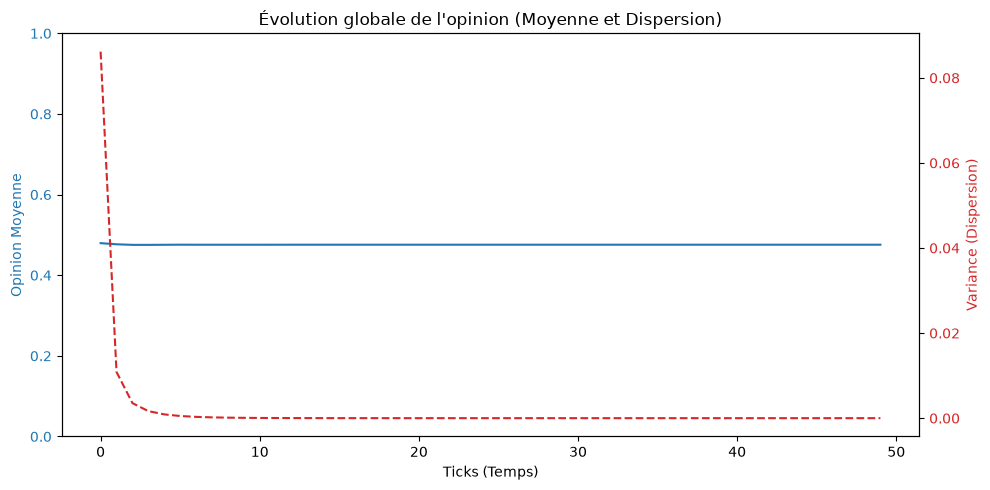

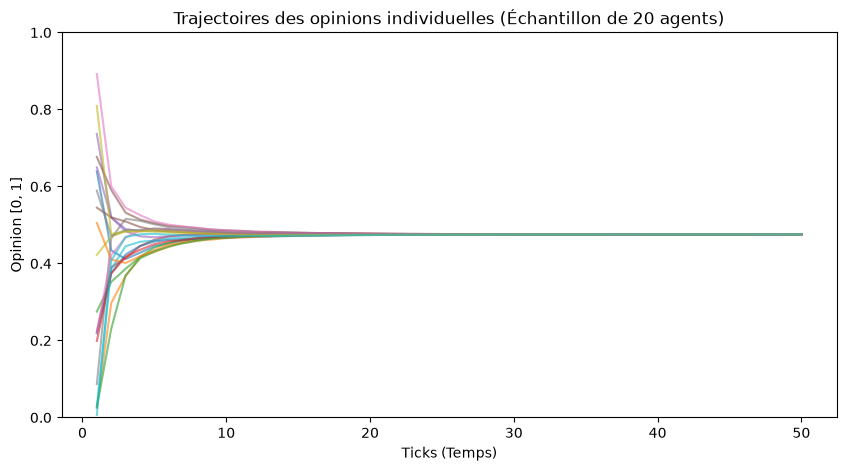

In [5]:
# Importation des bibliothèques nécessaires
import mesa
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Configuration de l'affichage des graphiques
%matplotlib inline
class CitizenAgent(mesa.Agent):
    """Un individu ayant une opinion qui évolue selon ses voisins."""
    def __init__(self, model, alpha):
        # Initialisation de l'agent (l'enregistrement dans le modèle est automatique dans Mesa 3)
        super().__init__(model)
        
        # Opinion initiale tirée aléatoirement entre 0 et 1
        self.opinion = self.model.random.random()
        # Niveau d'influence sociale
        self.alpha = alpha

    def step(self):
        # Récupération des voisins (Moore = 8 voisins alentours, sans inclure le centre)
        neighbors = self.model.grid.get_neighbors(self.pos, moore=True, include_center=False)
        
        if len(neighbors) > 0:
            # Calcul de l'opinion moyenne des voisins
            mean_opinion = np.mean([neighbor.opinion for neighbor in neighbors])
            
            # Mise à jour de l'opinion selon la formule mathématique du TD
            self.opinion = self.opinion + self.alpha * (mean_opinion - self.opinion)
class OpinionModel(mesa.Model):
    """Modèle simulant la formation de l'opinion publique sur une grille."""
    def __init__(self, width, height, alpha=0.2, seed=None):
        super().__init__(seed=seed)
        
        # Espace discret (grille) avec bords communicants (torus=True)
        self.grid = mesa.space.MultiGrid(width, height, torus=True)
        self.alpha = alpha
        
        # Initialisation de la population : on place un agent par case
        for _, (x, y) in self.grid.coord_iter():
            agent = CitizenAgent(self, self.alpha)
            self.grid.place_agent(agent, (x, y))
            
        # Mise en place du collecteur de données pour l'observation
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean([a.opinion for a in m.agents]),
                "Variance (Dispersion)": lambda m: np.var([a.opinion for a in m.agents])
            },
            agent_reporters={
                "Opinion": "opinion"
            }
        )

    def step(self):
        # 1. Collecter les données de l'état actuel
        self.datacollector.collect(self)
        # 2. Activer tous les agents dans un ordre aléatoire (Syntaxe Mesa 3)
        self.agents.shuffle_do("step")
# Paramètres du modèle
WIDTH = 10
HEIGHT = 10
ALPHA = 0.75 # Modifiez alpha pour observer son impact sur la vitesse de convergence
STEPS = 50

# Création et exécution du modèle
model = OpinionModel(width=WIDTH, height=HEIGHT, alpha=ALPHA, seed=42)

for i in range(STEPS):
    model.step()

# Récupération des données collectées
model_data = model.datacollector.get_model_vars_dataframe()
agent_data = model.datacollector.get_agent_vars_dataframe()

# Affichage des résultats globaux (Moyenne et Variance)
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Ticks (Temps)')
ax1.set_ylabel('Opinion Moyenne', color=color)
ax1.plot(model_data.index, model_data['Opinion Moyenne'], color=color, label="Moyenne")
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Variance (Dispersion)', color=color)
ax2.plot(model_data.index, model_data['Variance (Dispersion)'], color=color, linestyle='--', label="Variance")
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Évolution globale de l'opinion (Moyenne et Dispersion)")
fig.tight_layout()
plt.show()

# Affichage des trajectoires individuelles (Polarisation vs Consensus)
# On prend un échantillon de 20 agents pour la lisibilité
agent_opinions = agent_data.unstack(level=1)['Opinion']
sample_agents = agent_opinions.columns[:20]

plt.figure(figsize=(10, 5))
for agent_id in sample_agents:
    plt.plot(agent_opinions.index, agent_opinions[agent_id], alpha=0.6)

plt.title("Trajectoires des opinions individuelles (Échantillon de 20 agents)")
plt.xlabel("Ticks (Temps)")
plt.ylabel("Opinion [0, 1]")
plt.ylim(0, 1)
plt.show()

## 2. Implémentation de l'Agent

L'agent `CitizenAgent` possède une variable d'état `opinion`. À chaque itération (`step`), il récupère la liste de ses voisins sur la grille, calcule la moyenne de leurs opinions, et rapproche sa propre opinion de cette moyenne proportionnellement à son coefficient d'influence $\alpha$.

## 3. Implémentation du Modèle

Le modèle `OpinionModel` initialise l'espace (une grille `MultiGrid`), peuple cette grille avec nos agents, et gère le déroulement du temps et la collecte des données.

## 4. Exécution de la simulation et Observation

Nous allons maintenant instancier notre modèle, le faire tourner pendant un certain nombre de ticks, et observer l'évolution globale (la moyenne et la dispersion) ainsi que l'évolution individuelle pour identifier l'émergence d'un consensus ou de groupes.

## 5. Questions d'analyse et de compréhension

**Compréhension théorique (Dynamique des systèmes complexes)**
* Quel est l'impact précis du paramètre d'influence $\alpha$ sur la vitesse de convergence globale ? Que se passe-t-il visuellement sur le graphique si $\alpha$ est très proche de 0, ou à l'inverse, égal à 1 ?
* Dans le modèle actuel, le système finit presque toujours par converger vers un consensus global. Quel mécanisme mathématique de la méthode `step()` (mise à jour de l'opinion) rend la polarisation ou la création de groupes impossible à long terme avec cette configuration exacte ?
* En vous basant sur le protocole ODD, expliquez avec vos propres mots comment la notion d'"émergence" se manifeste dans les graphiques que vous avez générés. 

**Technique et manipulation de Mesa 3**
* Comment l'activation des agents est-elle gérée dans la nouvelle syntaxe de Mesa 3 (`self.agents.shuffle_do("step")`) par rapport aux itérations classiques sur des listes ? Quel est l'intérêt de l'ordre aléatoire ici ?
* Expliquez la différence entre `model_reporters` et `agent_reporters` lors de l'instanciation du `DataCollector`. Pourquoi est-il indispensable d'utiliser les deux pour observer à la fois le consensus et la dispersion ?
* Si un agent se trouve sur le bord de la grille (par exemple en `x=0`), comment le paramètre `torus=True` du `MultiGrid` affecte-t-il la récupération de ses voisins ?

**Ouverture et esprit critique (Pour aller plus loin)**
* Comment modifieriez-vous le code de l'agent pour introduire un "biais de confirmation" (c'est-à-dire qu'un agent n'est influencé par un voisin que si l'écart entre leurs deux opinions est inférieur à un seuil de tolérance $\epsilon$) ? Quel phénomène social émergerait alors ?
* Si nous devions modéliser un véritable réseau social (comme un graphe d'abonnés) plutôt qu'une grille spatiale, quelle structure topologique de Mesa utiliseriez-vous pour modéliser des "influenceurs" très connectés face à des utilisateurs isolés ?

A vous ....

---
# Réponses aux questions

## A. Compréhension théorique (Dynamique des systèmes complexes)

**1. Quel est l'impact du paramètre d'influence $\alpha$ sur la vitesse de convergence globale ? Que se passe-t-il visuellement si $\alpha$ est très proche de 0 ou égal à 1 ?**

Le paramètre $\alpha$ détermine le degré d'influence des voisins sur l'opinion d'un agent. Si $\alpha$ est proche de 0, les opinions changent lentement : les courbes restent presque plates et la variance diminue très peu. Si $\alpha = 1$, l'agent adopte directement la moyenne des opinions de ses voisins. Donc, plus $\alpha$ est grand, plus le changement est important à chaque étape et plus la convergence est rapide.

Pour le vérifier, la cellule suivante relance la simulation avec plusieurs valeurs de $\alpha$ : elle trace la variance (échelle logarithmique) et compte le nombre de ticks nécessaires pour que la variance passe sous $10^{-3}$ (moyenne sur 20 graines, limite de 300 ticks).

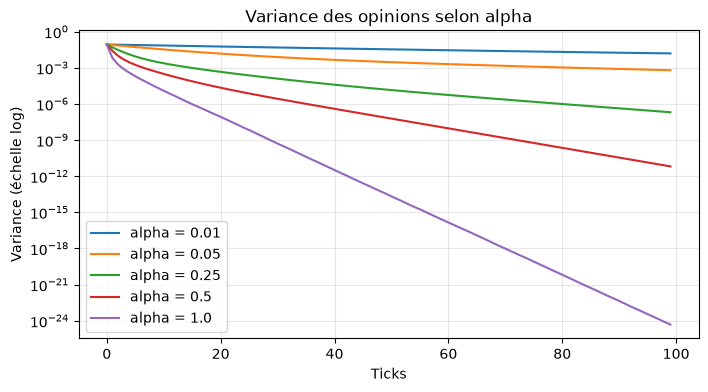

,alpha,ticks moyens,graines convergées (sur 20)
0,0.01,non atteint,0
1,0.05,101.0,20
2,0.25,18.8,20
3,0.50,8.6,20
4,1.00,4.2,20


In [6]:
# Vérification Q1 : effet de alpha sur la vitesse de convergence
alphas = [0.01, 0.05, 0.25, 0.5, 1.0]

# 1) Courbes de variance (échelle log), même graine pour tous
plt.figure(figsize=(8, 4))
for a in alphas:
    m = OpinionModel(width=10, height=10, alpha=a, seed=42)
    for _ in range(100):
        m.step()
    var = m.datacollector.get_model_vars_dataframe()["Variance (Dispersion)"]
    plt.semilogy(var.index, var, label=f"alpha = {a}")
plt.xlabel("Ticks")
plt.ylabel("Variance (échelle log)")
plt.title("Variance des opinions selon alpha")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2) Nombre de ticks pour atteindre une variance < 1e-3
def ticks_to_converge(alpha, seed, seuil=1e-3, max_ticks=300):
    m = OpinionModel(width=10, height=10, alpha=alpha, seed=seed)
    for t in range(max_ticks):
        if np.var([a.opinion for a in m.agents]) < seuil:
            return t
        m.step()
    return np.nan  # pas de convergence dans la limite

lignes = []
for a in alphas:
    ticks = [ticks_to_converge(a, s) for s in range(20)]
    n_ok = 20 - int(np.isnan(ticks).sum())
    lignes.append({
        "alpha": a,
        "ticks moyens": round(float(np.mean([t for t in ticks if not np.isnan(t)])), 1) if n_ok > 0 else "non atteint",
        "graines convergées (sur 20)": n_ok,
    })
pd.DataFrame(lignes)

**2. Quel mécanisme mathématique de `step()` rend la polarisation ou la création de groupes difficile à long terme ?**

La formule rapproche progressivement l'opinion de chaque agent de la moyenne des opinions de ses voisins. Elle peut s'écrire :

$$o_i^{t+1} = (1-\alpha)\,o_i^t + \alpha\,\bar{o}_{\mathcal{N}_i}^{\,t}$$

C'est une moyenne pondérée de deux opinions qui existent déjà. Comme l'agent se rapproche toujours de cette moyenne, il ne peut jamais s'en éloigner, et les différences entre les opinions diminuent progressivement. De plus, tous les voisins comptent quelle que soit leur opinion, et la grille est connectée (avec le tore), donc aucun groupe ne reste isolé. Le modèle favorise donc un consensus global plutôt que la polarisation ou la formation de groupes séparés.

Il faut quand même nuancer : le consensus est favorisé, mais il n'est pas garanti dans toutes les configurations possibles (par exemple si l'on change la règle d'influence, comme à la question 7).

**3. Comment la notion d'émergence se manifeste-t-elle dans les graphiques ?**

L'émergence se manifeste lorsque les interactions entre les agents produisent un comportement collectif sans intervention extérieure. Ici, chaque agent ne connaît que ses 8 voisins et ne sait rien de la population entière. Pourtant, sur le graphique global, la variance diminue jusqu'à presque zéro, et sur le graphique des trajectoires les opinions individuelles se rapprochent jusqu'à se confondre autour de la même valeur ($\approx 0{,}48$). Le consensus est donc une propriété du groupe, qui apparaît sans que personne l'ait programmée.

---
## B. Technique et manipulation de Mesa 3

**4. Comment l'activation des agents est-elle gérée avec `self.agents.shuffle_do("step")` ? Quel est l'intérêt de l'ordre aléatoire ?**

Cette instruction permet d'activer tous les agents dans un ordre aléatoire et d'exécuter leur méthode `step()`. Dans Mesa 3, les agents sont gardés automatiquement dans l'objet `self.agents` (un `AgentSet`), donc on n'a plus besoin de scheduler ni de liste à gérer soi-même. L'ordre aléatoire évite de toujours traiter les agents dans le même ordre : sinon, les premiers verraient toujours des opinions « anciennes » et les derniers des opinions « récentes », ce qui créerait un effet artificiel. Cela permet de représenter des interactions sociales moins dépendantes d'un ordre fixe.

**5. Quelle est la différence entre `model_reporters` et `agent_reporters` ? Pourquoi utiliser les deux ?**

`model_reporters` permet de collecter des informations globales sur la population, comme l'opinion moyenne et la variance (une valeur par tick). `agent_reporters` permet de suivre les informations de chaque agent individuellement (une valeur par agent et par tick). Les deux sont nécessaires pour observer à la fois l'évolution générale des opinions et les changements de chaque individu. Par exemple, la moyenne seule ne suffit pas : deux groupes à 0 et à 1 donneraient aussi une moyenne de 0,5, et c'est la variance qui permet de faire la différence.

**6. Comment `torus=True` affecte-t-il la récupération des voisins d'un agent situé sur le bord (ex : `x=0`) ?**

Le paramètre `torus=True` relie les bords opposés de la grille. Ainsi, un agent situé sur un bord peut avoir des voisins de l'autre côté de la grille. Cela permet de conserver le même principe de voisinage même pour les agents situés aux extrémités. La cellule suivante le vérifie pour l'agent en $(0,0)$.

In [8]:
# Vérification Q6 : voisins de l'agent situé en (0, 0) (coin de la grille)
m_test = OpinionModel(width=10, height=10, alpha=0.25, seed=1)
voisins = m_test.grid.get_neighbors((0, 0), moore=True, include_center=False)
print("Avec torus=True  :", len(voisins), "voisins ->", sorted(a.pos for a in voisins))

grille_plate = mesa.space.MultiGrid(10, 10, torus=False)
cases = grille_plate.get_neighborhood((0, 0), moore=True, include_center=False)
print("Avec torus=False :", len(cases), "voisins ->", sorted(cases))

Avec torus=True  : 8 voisins -> [(0, 1), (0, 9), (1, 0), (1, 1), (1, 9), (9, 0), (9, 1), (9, 9)]
Avec torus=False : 3 voisins -> [(0, 1), (1, 0), (1, 1)]


---
## C. Ouverture et esprit critique

**7. Comment introduire un biais de confirmation (seuil de tolérance $\epsilon$) ?** 

Le code ci-dessous (cellule suivante) ajoute la classe `BiasedCitizenAgent`, dont la méthode `step()` ne tient compte que des voisins proches, puis le modèle `BiasedOpinionModel`. Il est exécuté avec $\alpha = 0{,}5$, $\epsilon = 0{,}2$ et 100 ticks.

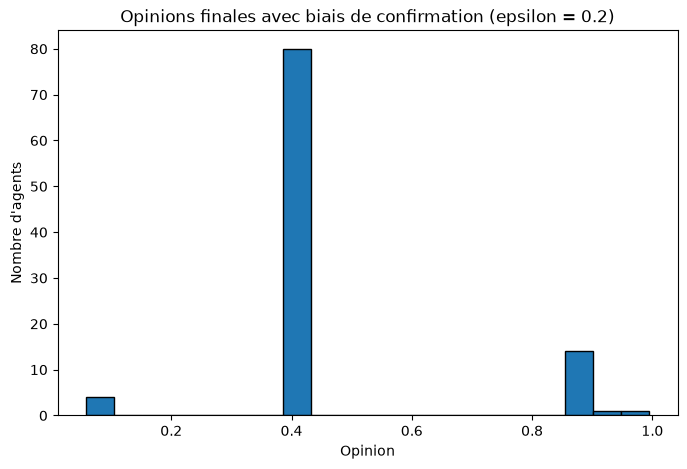

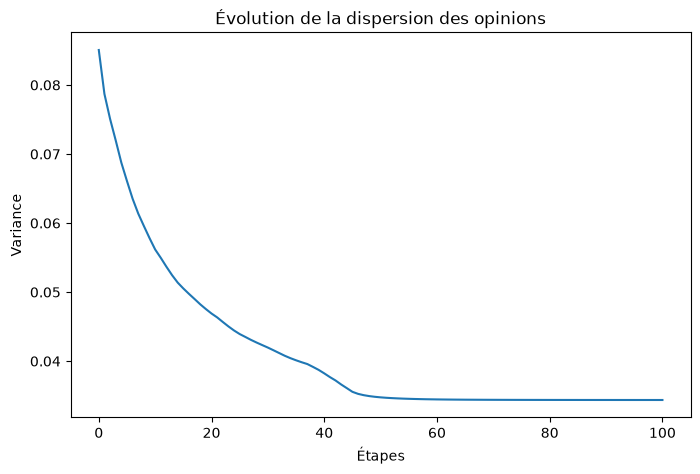

In [9]:

import mesa
import numpy as np
import matplotlib.pyplot as plt


class CitizenAgent(mesa.Agent):
    def __init__(self, model, alpha):
        super().__init__(model)
        self.opinion = self.random.random()
        self.alpha = alpha

    def step(self):
        neighbors = self.model.grid.get_neighbors(
            self.pos,
            moore=True,
            include_center=False
        )

        if len(neighbors) > 0:
            mean_opinion = np.mean(
                [neighbor.opinion for neighbor in neighbors]
            )

            self.opinion = self.opinion + self.alpha * (
                mean_opinion - self.opinion
            )


class OpinionModel(mesa.Model):
    def __init__(self, width, height, alpha=0.2, seed=None):
        super().__init__(seed=seed)

        self.grid = mesa.space.MultiGrid(
            width, height, torus=True
        )

        for _, (x, y) in self.grid.coord_iter():
            agent = CitizenAgent(self, alpha)
            self.grid.place_agent(agent, (x, y))

        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean(
                    [a.opinion for a in m.agents]
                ),
                "Variance (Dispersion)": lambda m: np.var(
                    [a.opinion for a in m.agents]
                )
            },
            agent_reporters={
                "Opinion": "opinion"
            }
        )

        self.datacollector.collect(self)

    def step(self):
        self.agents.shuffle_do("step")
        self.datacollector.collect(self)


class BiasedCitizenAgent(CitizenAgent):
    """Agent influencé seulement par les voisins proches de son opinion."""

    def __init__(self, model, alpha, epsilon):
        super().__init__(model, alpha)
        self.epsilon = epsilon

    def step(self):
        neighbors = self.model.grid.get_neighbors(
            self.pos,
            moore=True,
            include_center=False
        )

        close = [
            n.opinion
            for n in neighbors
            if abs(n.opinion - self.opinion) < self.epsilon
        ]

        if len(close) > 0:
            mean_close = np.mean(close)

            self.opinion = self.opinion + self.alpha * (
                mean_close - self.opinion
            )


class BiasedOpinionModel(OpinionModel):
    def __init__(
        self, width, height,
        alpha=0.5, epsilon=0.2, seed=None
    ):
        super().__init__(
            width=width,
            height=height,
            alpha=alpha,
            seed=seed
        )

        # Remplacer les agents classiques par des agents biaisés
        for agent in list(self.agents):
            self.grid.remove_agent(agent)
            agent.remove()

        for _, (x, y) in self.grid.coord_iter():
            agent = BiasedCitizenAgent(self, alpha, epsilon)
            self.grid.place_agent(agent, (x, y))

        self.epsilon = epsilon

        # Réinitialiser la collecte pour les nouveaux agents
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Opinion Moyenne": lambda m: np.mean(
                    [a.opinion for a in m.agents]
                ),
                "Variance (Dispersion)": lambda m: np.var(
                    [a.opinion for a in m.agents]
                )
            },
            agent_reporters={
                "Opinion": "opinion"
            }
        )

        self.datacollector.collect(self)

    def step(self):
        self.agents.shuffle_do("step")
        self.datacollector.collect(self)


# Création et exécution du modèle
mb = BiasedOpinionModel(
    width=10,
    height=10,
    alpha=0.5,
    epsilon=0.2,
    seed=42
)

for _ in range(100):
    mb.step()


# Histogramme des opinions finales
ops = [a.opinion for a in mb.agents]

plt.figure(figsize=(8, 5))
plt.hist(ops, bins=20, edgecolor="black")
plt.title(
    "Opinions finales avec biais de confirmation (epsilon = 0.2)"
)
plt.xlabel("Opinion")
plt.ylabel("Nombre d'agents")
plt.show()


# Évolution de la variance
data = mb.datacollector.get_model_vars_dataframe()

plt.figure(figsize=(8, 5))
plt.plot(data["Variance (Dispersion)"])
plt.title("Évolution de la dispersion des opinions")
plt.xlabel("Étapes")
plt.ylabel("Variance")
plt.show()


**Réponse à la question 7**

Pour introduire le biais de confirmation, nous avons modifié la méthode `step()` de l'agent afin qu'il soit influencé uniquement par les voisins dont l'opinion est suffisamment proche de la sienne, selon un seuil `epsilon` (condition `abs(n.opinion - self.opinion) < self.epsilon`).

Cette modification peut entraîner la formation de groupes d'opinions similaires et favoriser la polarisation, car les agents échangent principalement avec des personnes qui partagent des opinions proches des leurs.

Les résultats vont dans ce sens. Contrairement au modèle de base, la variance ne tend pas vers zéro : elle passe d'environ $0{,}085$ à $0{,}034$ puis se stabilise vers le tick 60, donc il n'y a pas de consensus. L'histogramme des opinions finales montre plusieurs groupes : environ 80 agents autour de $0{,}4$, un petit groupe de 4 agents vers $0{,}07$ et environ 16 agents vers $0{,}9$. Ces groupes ne s'influencent plus entre eux, comme des chambres d'écho.

**8. Quelle structure de Mesa utiliser pour modéliser un vrai réseau social, avec des influenceurs très connectés et des utilisateurs isolés ?**

On peut utiliser un graphe avec `mesa.space.NetworkGrid`, basé sur une structure de réseau telle que `networkx.Graph` ou `networkx.DiGraph`.

* Les nœuds représentent les utilisateurs.
* Les arêtes représentent les relations ou les abonnements.
* Les influenceurs sont représentés par des nœuds ayant beaucoup de connexions.
* Les utilisateurs isolés ont peu de connexions, ou aucune.

Un graphe orienté (`DiGraph`) est particulièrement utile si on veut représenter le fait que l'utilisateur A suit B sans que B suive nécessairement A.